In [72]:
### The time stamp for the MassiveHistorical data is not quite right

In [50]:
import sys
sys.path.insert(0, "/home/magicyu/Documents/finance_projects/torch_pricer")

In [284]:
from __future__ import annotations

import sys
from pathlib import Path

from data_pipeline.download import download_dividends, download_equity, download_rates
from pandas import Timestamp


TICKERS = ["SPY", "SPX"]
START = "2026-09-08"
END = "2026-09-30"

DOWNLOAD_EQUITY = True
DOWNLOAD_RATES = True
DOWNLOAD_DIVIDENDS = True
DATA_DIR = "/home/magicyu/Documents/finance_projects/torch_pricer/market_data"

RATES_PROVIDER = "massive"  # or "fred"
RATES_LOOKBACK_DAYS = 14
DIVIDEND_HORIZON_DAYS = 365
REFRESH = False  # refetch rates and dividends even if cached

if DOWNLOAD_EQUITY:
    results = download_equity(TICKERS, START, END, data_dir=DATA_DIR, on_progress=print)
    failed = [r.label for r in results if not r.ok]
    if failed:
        print(f"equity failed for {failed}; rerun to retry them")
if DOWNLOAD_RATES:
    rates = download_rates(START, END, provider=RATES_PROVIDER, lookback_days=RATES_LOOKBACK_DAYS,
                   refresh=REFRESH, data_dir=DATA_DIR, on_progress=print)
if DOWNLOAD_DIVIDENDS:
    dividends = download_dividends(TICKERS, START, END, horizon_days=DIVIDEND_HORIZON_DAYS,
                       refresh=REFRESH, data_dir=DATA_DIR, on_progress=print)

equity 2026-09-08: 252,847 rows
equity 2026-09-09: 251,238 rows
equity 2026-09-10: 287,537 rows
equity 2026-09-11: 272,171 rows
equity 2026-09-14: 273,782 rows
equity 2026-09-15: 257,676 rows
equity 2026-09-16: 339,789 rows
equity 2026-09-17: 294,271 rows
equity 2026-09-18: 277,391 rows
equity 2026-09-21: 376,928 rows
equity 2026-09-22: 265,408 rows
equity 2026-09-23: 299,074 rows
equity 2026-09-24: 294,236 rows
equity 2026-09-25: 296,671 rows
equity 2026-09-28: 306,651 rows
equity 2026-09-29: 282,510 rows
equity 2026-09-30: 287,848 rows
rates (massive) 2026-08-25 to 2026-09-30: 182 rows
dividends SPY 2026-09-08 to 2027-09-30: 1 rows
dividends SPX: index, no dividends: skipped


In [289]:
from data_pipeline.option_equity_historical_data_loader import MassiveHistoricalDataLoader

loader = MassiveHistoricalDataLoader(data_dir=DATA_DIR)

market = loader.load_market(
    dates="2026-09-10",
    tickers=["SPX"],
)



In [290]:
market

,session_date,timestamp,underlying,option_root,option_ticker,expiration,option_type,strike,option_open,option_high,...,underlying_high,underlying_low,underlying_close,underlying_volume,underlying_transactions,underlying_window_start_ns,underlying_timestamp,spot,matched_underlying,underlying_age
0,2026-09-10,2026-09-10 09:30:00-04:00,SPX,SPXW,O:SPXW260910C07500000,2026-09-10,call,7500.0,93.69,94.20,...,7597.09,7591.37,7593.82,None,None,1.789047e+18,2026-09-10 09:30:00-04:00,7593.82,True,0 days
1,2026-09-10,2026-09-10 09:30:00-04:00,SPX,SPXW,O:SPXW260910C07505000,2026-09-10,call,7505.0,88.80,88.84,...,7597.09,7591.37,7593.82,None,None,1.789047e+18,2026-09-10 09:30:00-04:00,7593.82,True,0 days
2,2026-09-10,2026-09-10 09:30:00-04:00,SPX,SPXW,O:SPXW260910C07540000,2026-09-10,call,7540.0,57.00,57.00,...,7597.09,7591.37,7593.82,None,None,1.789047e+18,2026-09-10 09:30:00-04:00,7593.82,True,0 days
3,2026-09-10,2026-09-10 09:30:00-04:00,SPX,SPXW,O:SPXW260910C07545000,2026-09-10,call,7545.0,52.40,52.40,...,7597.09,7591.37,7593.82,None,None,1.789047e+18,2026-09-10 09:30:00-04:00,7593.82,True,0 days
4,2026-09-10,2026-09-10 09:30:00-04:00,SPX,SPXW,O:SPXW260910C07550000,2026-09-10,call,7550.0,49.89,50.80,...,7597.09,7591.37,7593.82,None,None,1.789047e+18,2026-09-10 09:30:00-04:00,7593.82,True,0 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143443,2026-09-10,2026-09-10 16:59:00-04:00,SPX,SPXW,O:SPXW260918P07410000,2026-09-18,put,7410.0,23.10,23.10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,False,NaT
143444,2026-09-10,2026-09-10 16:59:00-04:00,SPX,SPXW,O:SPXW260918P07440000,2026-09-18,put,7440.0,27.35,27.38,...,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,False,NaT
143445,2026-09-10,2026-09-10 16:59:00-04:00,SPX,SPXW,O:SPXW260921P07500000,2026-09-21,put,7500.0,42.80,42.80,...,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,False,NaT
143446,2026-09-10,2026-09-10 16:59:00-04:00,SPX,SPXW,O:SPXW260930C07800000,2026-09-30,call,7800.0,19.20,19.20,...,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,False,NaT


In [291]:
### filter the calibration to time between 3:30 pm to 4: 00 pm
from datetime import time

CALIB_START = time(15, 30)
CALIB_END = time(16, 0)  # exclusive: the 15:59 minute bar covers up to 16:00

bar_time = market.timestamp.dt.tz_convert("America/New_York").dt.time
in_window = (bar_time >= CALIB_START) & (bar_time <= CALIB_END)

df_calibration = market[(market.option_root == "SPXW") & in_window]
assert not df_calibration.empty, "no SPXW bars in the 15:30-16:00 calibration window"
df_calibration


,session_date,timestamp,underlying,option_root,option_ticker,expiration,option_type,strike,option_open,option_high,...,underlying_high,underlying_low,underlying_close,underlying_volume,underlying_transactions,underlying_window_start_ns,underlying_timestamp,spot,matched_underlying,underlying_age
122610,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07550000,2026-09-10,call,7550.0,40.10,40.10,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122611,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07565000,2026-09-10,call,7565.0,25.50,25.50,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122612,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07570000,2026-09-10,call,7570.0,19.80,20.50,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122613,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07575000,2026-09-10,call,7575.0,15.30,15.68,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122614,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07580000,2026-09-10,call,7580.0,10.90,11.21,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137479,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261120P06950000,2026-11-20,put,6950.0,58.85,58.85,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137480,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261120P07000000,2026-11-20,put,7000.0,63.55,63.55,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137481,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261218C09000000,2026-12-18,call,9000.0,1.80,1.80,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137483,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261218P06400000,2026-12-18,put,6400.0,42.50,42.50,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days


In [292]:
### slice the call put parity pairs
# One row per (minute, expiry, strike) where both the call and the put traded in that
# minute, with parity = C - P. Box-spread prints (2 strikes in the minute, all 4 legs
# with the same volume) are flagged: they are traded as one package, so they price the
# box financing rate, which runs ~10-55bp above T-bills.
import numpy as np
import pandas as pd

MONEYNESS_BAND = 0.10  # keep |K / S - 1| < 10%, far wing trade prints are stale
YEAR_SECONDS = 365 * 24 * 3600


def build_parity_pairs(df: pd.DataFrame) -> pd.DataFrame:
    keys = ["timestamp", "option_root", "expiration", "strike"]
    prices = df.pivot_table(index=keys, columns="option_type", values="option_close", aggfunc="last")
    volumes = df.pivot_table(index=keys, columns="option_type", values="option_volume", aggfunc="sum")
    pairs = (
        prices.join(volumes.add_suffix("_volume"))
        .dropna(subset=["call", "put"])
        .join(df.groupby(keys).underlying_close.last().rename("spot"))
        .dropna(subset=["spot"])
        .reset_index()
    )
    pairs["strike"] = pairs["strike"].astype(float)  # nullable Float64 -> float
    pairs["parity"] = pairs["call"] - pairs["put"]

    # SPXW is PM-settled: expiry at 16:00 ET on the expiration date
    expiry_ts = (pairs.expiration + pd.Timedelta(hours=16)).dt.tz_localize("America/New_York")
    pairs["T"] = (expiry_ts - pairs.timestamp).dt.total_seconds() / YEAR_SECONDS
    pairs = pairs[(pairs["T"] > 0) & ((pairs.strike / pairs.spot - 1).abs() < MONEYNESS_BAND)]

    # the per-minute intercept needs at least 2 strikes in the same (expiry, minute)
    by_minute = ["option_root", "expiration", "timestamp"]
    pairs = pairs[pairs.groupby(by_minute).strike.transform("size") >= 2].copy()

    grouped = pairs.groupby(by_minute)
    one_volume = (
        (pairs.call_volume == pairs.put_volume)
        & (grouped.call_volume.transform("nunique") == 1)
        & (grouped.put_volume.transform("nunique") == 1)
    )
    pairs["is_box"] = (grouped.strike.transform("size") == 2) & one_volume
    return pairs.reset_index(drop=True)


parity_pairs = build_parity_pairs(df_calibration[df_calibration.option_root == "SPXW"])
print(f"{len(parity_pairs)} pairs, {parity_pairs.is_box.sum()} in box prints, "
      f"{parity_pairs.expiration.nunique()} expiries")
parity_pairs

1357 pairs, 0 in box prints, 9 expiries


,timestamp,option_root,expiration,strike,call,put,call_volume,put_volume,spot,parity,T,is_box
0,2026-09-10 15:30:00-04:00,SPXW,2026-09-10,7550.0,40.10,0.07,1.0,27.0,7587.89,40.03,0.000057,False
1,2026-09-10 15:30:00-04:00,SPXW,2026-09-10,7565.0,24.00,0.20,5.0,78.0,7587.89,23.80,0.000057,False
2,2026-09-10 15:30:00-04:00,SPXW,2026-09-10,7570.0,19.20,0.37,18.0,103.0,7587.89,18.83,0.000057,False
3,2026-09-10 15:30:00-04:00,SPXW,2026-09-10,7575.0,14.10,0.65,21.0,168.0,7587.89,13.45,0.000057,False
4,2026-09-10 15:30:00-04:00,SPXW,2026-09-10,7580.0,9.90,1.30,49.0,645.0,7587.89,8.60,0.000057,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1352,2026-09-10 16:00:00-04:00,SPXW,2026-09-11,7730.0,0.50,136.70,1.0,3.0,7591.79,-136.20,0.002740,False
1353,2026-09-10 16:00:00-04:00,SPXW,2026-09-11,7920.0,0.05,326.14,8.0,1.0,7591.79,-326.09,0.002740,False
1354,2026-09-10 16:00:00-04:00,SPXW,2026-09-18,7590.0,73.98,65.87,2.0,4.0,7591.79,8.11,0.021918,False
1355,2026-09-10 16:00:00-04:00,SPXW,2026-09-18,7670.0,33.00,104.65,1.0,1.0,7591.79,-71.65,0.021918,False


In [293]:
### regress the call put parity to get the discount factor, per expiry
# Parity: C - P = A_t - D * K, with D = exp(-r T) and A_t = S_t * exp(-q T).
# Per (root, expiry), OLS of (C - P) on K with one intercept A_t per minute (spot moves
# between minutes, so a single intercept would be wrong). Demeaning within each minute
# gives the slope without estimating every intercept: -D = sum(K_dm * P_dm) / sum(K_dm^2).
# The intercepts then come back as A_t = mean(C - P) + D * mean(K), and A_t / S_t
# estimates exp(-q T). Then r = -ln(D) / T and q = -ln(A_t / S_t) / T, both continuous.


def regress_parity(pairs: pd.DataFrame, exclude_boxes: bool = False) -> dict:
    p = pairs[~pairs.is_box] if exclude_boxes else pairs
    by_minute = ["option_root", "expiration", "timestamp"]
    p = p[p.groupby(by_minute).strike.transform("size") >= 2]
    empty = {"discount": np.nan, "discount_se": np.nan, "div_discount": np.nan,
             "div_discount_se": np.nan, "r": np.nan, "r_se": np.nan, "q": np.nan, "q_se": np.nan,
             "T": np.nan, "n_pairs": 0, "n_minutes": 0}
    if p.empty:
        return empty
    grouped = p.groupby(by_minute)
    k_dm = (p.strike - grouped.strike.transform("mean")).to_numpy()
    p_dm = (p.parity - grouped.parity.transform("mean")).to_numpy()

    discount = -(k_dm @ p_dm) / (k_dm @ k_dm)
    resid = p_dm + discount * k_dm

    # minute-clustered standard error: trades in one minute share spot and timing noise
    n_minutes = grouped.ngroups
    cluster_score = pd.Series(k_dm * resid).groupby(grouped.ngroup().to_numpy()).sum()
    discount_se = np.sqrt((cluster_score**2).sum()) / (k_dm @ k_dm)
    if n_minutes < 2 or len(p) - n_minutes - 1 <= 0:
        discount_se = np.nan  # an exact fit (e.g. one box print) has no residual to measure noise from

    # per-minute intercepts A_t, scaled by that minute's spot
    minute = grouped.agg(parity=("parity", "mean"), strike=("strike", "mean"), spot=("spot", "first"))
    div_discount_t = (minute.parity + discount * minute.strike) / minute.spot
    # spread across minutes, plus the error in D carried through D * mean(K) / S_t
    div_discount_se = np.sqrt(
        div_discount_t.var() / n_minutes + (discount_se * (minute.strike / minute.spot).mean()) ** 2
    )
    div_discount = div_discount_t.mean()

    # continuous rate and dividend yield; se via d(-ln x / T) = dx / (x T)
    T = p["T"].mean()
    return {"discount": discount, "discount_se": discount_se,
            "div_discount": div_discount, "div_discount_se": div_discount_se,
            "r": -np.log(discount) / T, "r_se": discount_se / (discount * T),
            "q": -np.log(div_discount) / T, "q_se": div_discount_se / (div_discount * T),
            "T": T, "n_pairs": len(p), "n_minutes": n_minutes}


rows = {}
for (root, expiration), g in parity_pairs.groupby(["option_root", "expiration"]):
    fit = regress_parity(g)
    fit["discount_ex_boxes"] = regress_parity(g, exclude_boxes=True)["discount"]
    rows[(root, expiration)] = fit
parity_fit = pd.DataFrame(rows).T.rename_axis(["option_root", "expiration"]).sort_index(level="expiration")
parity_fit

discount  discount_se  div_discount  div_discount_se  \
option_root expiration                                                         
SPXW        2026-09-10  1.000835     0.000942      1.000903         0.000943   
            2026-09-11  0.999741     0.000329      1.000127         0.000330   
            2026-09-14  1.003869     0.000990      1.004352         0.000993   
            2026-09-15  1.002767     0.003590      1.003205         0.003596   
            2026-09-17  1.000468     0.002007      1.000973         0.002006   
            2026-09-18  0.999131     0.000608      1.000031         0.000612   
            2026-09-24  1.026500          NaN      1.027981              NaN   
            2026-09-25  1.022571     0.006119      1.024287         0.006167   
            2026-09-30  0.991400          NaN      0.993086              NaN   

                                r       r_se          q       q_se         T  \
option_root expiration                                                         
SPXW        2026-09-10 -27.841127  31.416987 -30.104401  31.441598  0.000030   
            2026-09-11   0.093668   0.118896  -0.045949   0.119237  0.002766   
            2026-09-14  -0.351529   0.089813  -0.395304   0.089996  0.010984   
            2026-09-15  -0.201360   0.260909  -0.233211   0.261189  0.013723   
            2026-09-17  -0.024355   0.104476  -0.050630   0.104374  0.019201   
            2026-09-18   0.039641   0.027738  -0.001407   0.027870  0.021942   
            2026-09-24  -0.681424        NaN  -0.718997        NaN  0.038383   
            2026-09-25  -0.542754   0.145499  -0.583512   0.146392  0.041124   
            2026-09-30   0.157618        NaN   0.126606        NaN  0.054798   

                        n_pairs  n_minutes  discount_ex_boxes  
option_root expiration                                         
SPXW        2026-09-10    511.0       30.0           1.000835  
            2026-09-11    667.0       31.0           0.999741  
            2026-09-14     98.0       23.0           1.003869  
            2026-09-15     32.0       12.0           1.002767  
            2026-09-17     10.0        4.0           1.000468  
            2026-09-18     30.0       10.0           0.999131  
            2026-09-24      2.0        1.0           1.026500  
            2026-09-25      5.0        2.0           1.022571  
            2026-09-30      2.0        1.0           0.991400

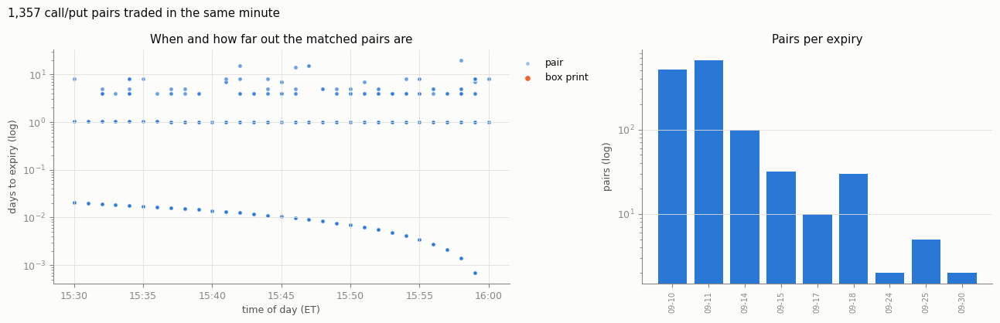

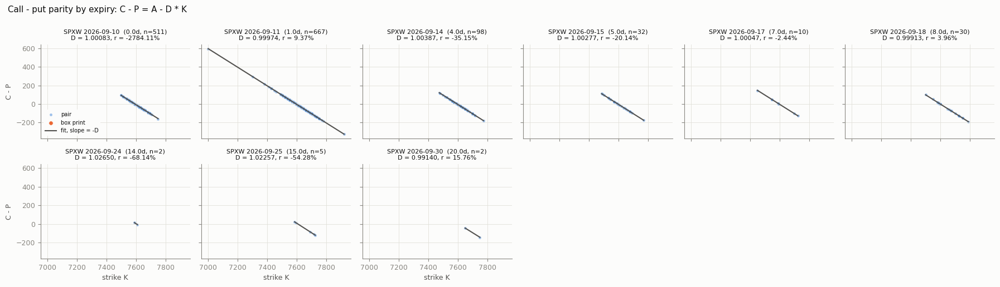

In [294]:
### plot the call put parity regression, per expiry
# One panel per (root, expiry): raw C - P against strike K. The fitted line has slope -D
# from regress_parity. Spot moves between minutes, which shifts each minute's intercept
# A_t by a few points, so the line uses the average intercept mean(C - P + D * K).
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
PAIR_COLOR, BOX_COLOR = "#2a78d6", "#eb6834"  # categorical slots 1-2, validated all-pairs

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})


def plot_parity_regression(pairs: pd.DataFrame, n_cols: int = 6, share_axes: bool = True):
    """C - P against K for every (root, expiry) in ``pairs``, with the fitted line -D * K + A."""
    by_minute = ["option_root", "expiration", "timestamp"]
    pairs = pairs[pairs.groupby(by_minute).strike.transform("size") >= 2]
    groups = sorted(pairs.groupby(["option_root", "expiration"]), key=lambda kv: kv[1]["T"].mean())
    n_rows = -(-len(groups) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.6 * n_rows),
                             sharex=share_axes, sharey=share_axes, squeeze=False)

    for ax, ((root, expiration), g) in zip(axes.flat, groups):
        fit = regress_parity(g)
        D, T = fit["discount"], fit["T"]
        is_box = g.is_box.to_numpy()
        ring = {"edgecolors": SURFACE, "linewidths": 0.6}
        ax.scatter(g.strike[~is_box], g.parity[~is_box], s=14, color=PAIR_COLOR, alpha=0.45,
                   label="pair", **ring)
        ax.scatter(g.strike[is_box], g.parity[is_box], s=30, color=BOX_COLOR, label="box print", **ring)

        intercept = (g.parity + D * g.strike).mean()
        line_x = np.array([g.strike.min(), g.strike.max()])
        ax.plot(line_x, intercept - D * line_x, color=INK_2, linewidth=1.5, label="fit, slope = -D")
        ax.set_title(f"{root} {expiration:%Y-%m-%d}  ({T * 365:.1f}d, n={len(g)})\n"
                     f"D = {D:.5f}, r = {fit['r']:.2%}", fontsize=8, color=INK)

    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    for ax in axes[-1, :]:
        ax.set_xlabel("strike K")
    for ax in axes[:, 0]:
        ax.set_ylabel("C - P")
    axes[0, 0].legend(loc="lower left", fontsize=7, facecolor=SURFACE, edgecolor="none", framealpha=1)
    fig.suptitle("Call - put parity by expiry: C - P = A - D * K", color=INK, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    return fig


### plot where the call put parity pairs are
# Left: each pair by time of day and days to expiry (log). Right: number of pairs per
# (root, expiry), sorted by expiry. Box prints are drawn on top in the second color.
def plot_parity_coverage(pairs: pd.DataFrame):
    """Coverage of ``pairs``: when they traded, how far out, and how many per expiry."""
    is_box = pairs.is_box.to_numpy()
    days = (pairs["T"] * 365).to_numpy()
    ring = {"edgecolors": SURFACE, "linewidths": 0.6}

    fig, (ax_time, ax_count) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
    ax_time.scatter(pairs.timestamp[~is_box], days[~is_box], s=14, color=PAIR_COLOR, alpha=0.45,
                    label="pair", **ring)
    ax_time.scatter(pairs.timestamp[is_box], days[is_box], s=30, color=BOX_COLOR, label="box print", **ring)
    ax_time.set_yscale("log")
    ax_time.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=pairs.timestamp.dt.tz))
    ax_time.set(xlabel="time of day (ET)", ylabel="days to expiry (log)",
                title="When and how far out the matched pairs are")
    ax_time.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)

    counts = pairs.groupby(["option_root", "expiration"]).size().sort_index(level="expiration")
    labels = [f"{e:%m-%d}" + ("" if root == "SPXW" else " SPX") for root, e in counts.index]
    ax_count.bar(range(len(counts)), counts.to_numpy(), color=PAIR_COLOR, width=0.8)
    ax_count.set_yscale("log")
    ax_count.set_xticks(range(len(counts)), labels, rotation=90, fontsize=7)
    ax_count.set(ylabel="pairs (log)", title="Pairs per expiry")
    ax_count.grid(axis="x", visible=False)

    fig.suptitle(f"{len(pairs):,} call/put pairs traded in the same minute", color=INK, x=0.01, ha="left")
    fig.tight_layout()
    return fig


fig = plot_parity_coverage(parity_pairs)
plt.show()


fig = plot_parity_regression(parity_pairs)
plt.show()

In [295]:
### getting the treasury rates curve

from data_pipeline.download import download_rates
from data_pipeline.rates import TREASURY_CMT_SERIES, TREASURY_TENORS, RatesDataLoader

par = RatesDataLoader(RATES_PROVIDER, data_dir=DATA_DIR).yields_as_of("2026-09-08", lag_days=0)
treasury_zero_rate_curve = treasury_zero_curve(par.tenors, par.yields_pct)
treasury_zero_rate_curve

RateCurve('UST', 7 pillars)

In [296]:
T = np.array([7 / 365, 0.2, 0.3, 0.5, 1.0, 2.0, 20.0])
zero = treasury_curve.instantaneous_forward(T).detach().numpy()     
zero

array([0.03803964, 0.03979101, 0.04171698, 0.04171698, 0.04589344,
       0.04654367, 0.05819437])

In [297]:
par.yields_pct

array([3.81, 3.94, 4.15, 4.39, 4.57, 4.8 , 5.25])

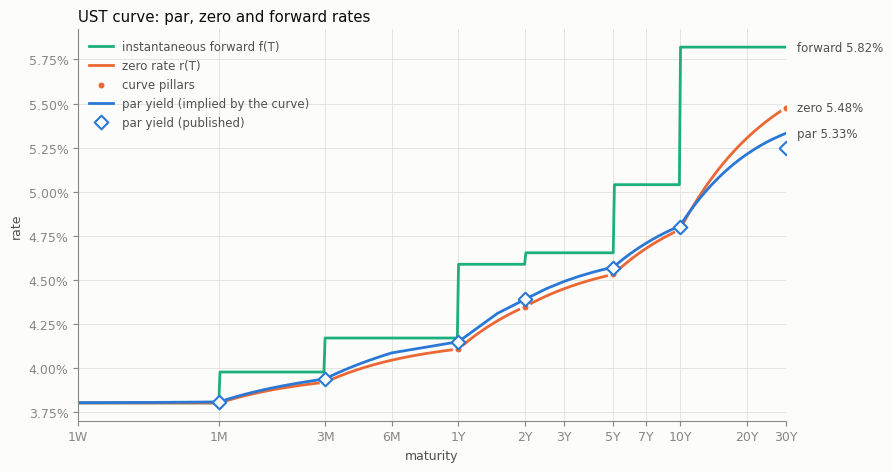

In [301]:
### plot a rate curve's par, zero and instantaneous forward rates
# All three are views of one discount function D(T), so the curve alone defines them:
#   zero     r(T) = -ln D(T) / T
#   forward  f(T) = -d ln D / dT (here over a one-basis-point-of-a-year window)
#   par      up to 6M a bill yield (1 / D(T) - 1) / T; beyond, the semiannual coupon that
#            prices a bond at par, 2 (1 - D(T)) / sum_i D(t_i) over t_i = 0.5, 1.0, ..., T.
# The curve's par yields are not the published ones: it keeps zeros only at the quoted
# tenors, so coupon dates in between are interpolated (up to ~8bp apart at 30Y).
# Pass ``published`` (a ParYieldSnapshot) to overlay what Treasury actually quoted.
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
PAR_COLOR, ZERO_COLOR, FORWARD_COLOR = "#2a78d6", "#eb6834", "#1baf7a"  # categorical slots 1-3
TENOR_LABELS = {1 / 52: "1W", 1 / 12: "1M", 0.25: "3M", 0.5: "6M", 1: "1Y", 2: "2Y", 3: "3Y", 5: "5Y",
                7: "7Y", 10: "10Y", 20: "20Y", 30: "30Y"}
COUPON_PERIOD = 0.5


def par_rates(curve, max_tenor: float) -> tuple[np.ndarray, np.ndarray]:
    """The curve's par yields: bills on a fine grid to 6M, then every half-year coupon tenor."""
    bills = np.geomspace(1 / 52, COUPON_PERIOD, 60)
    bill_par = (1.0 / curve.discount(bills).detach().numpy() - 1.0) / bills
    coupon_dates = COUPON_PERIOD * np.arange(1, int(round(max_tenor / COUPON_PERIOD)) + 1)
    dfs = curve.discount(coupon_dates).detach().numpy()
    bond_par = (1.0 - dfs) / (COUPON_PERIOD * np.cumsum(dfs))  # tenor t_n uses coupons t_1..t_n
    return np.concatenate([bills, coupon_dates[1:]]), np.concatenate([bill_par, bond_par[1:]])


def plot_rate_curves(curve, max_tenor: float | None = None, published=None, title: str | None = None):
    """Par, zero and instantaneous forward rates of ``curve``, on one rates axis."""
    pillars = curve.pillar_times.numpy()
    max_tenor = float(max_tenor or pillars.max())
    # stop one forward bump short of the end: past the last pillar the curve is flat by construction
    t = np.geomspace(1 / 52, max_tenor - 2e-4, 600)
    zero = 100 * curve.zero_rate(t).detach().numpy()
    forward = 100 * curve.instantaneous_forward(t).detach().numpy()
    par_t, par = par_rates(curve, max_tenor)
    par = 100 * par

    fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.plot(t, forward, color=FORWARD_COLOR, linewidth=2, label="instantaneous forward f(T)")
    ax.plot(t, zero, color=ZERO_COLOR, linewidth=2, label="zero rate r(T)")
    ax.scatter(pillars, 100 * curve.pillar_zeros.detach().numpy(), s=40, color=ZERO_COLOR,
               edgecolors=SURFACE, linewidths=2, zorder=3, label="curve pillars")
    ax.plot(par_t, par, color=PAR_COLOR, linewidth=2, label="par yield (implied by the curve)")
    if published is not None:
        ax.scatter(published.tenors, published.yields_pct, s=48, marker="D", facecolors=SURFACE,
                   edgecolors=PAR_COLOR, linewidths=1.5, zorder=4, label="par yield (published)")

    # direct labels at the long end, in ink, next to each series' last point
    for value, name in [(forward[-1], "forward"), (zero[-1], "zero"), (par[-1], "par")]:
        ax.annotate(f"{name} {value:.2f}%", (max_tenor, value), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK_2, annotation_clip=False)

    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([x for x in TENOR_LABELS if x <= max_tenor]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: TENOR_LABELS.get(x, "")))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}%"))
    ax.set_xlim(t[0], max_tenor)
    ax.set_xlabel("maturity", color=INK_2)
    ax.set_ylabel("rate", color=INK_2)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.legend(loc="upper left", frameon=False, fontsize=8.5, labelcolor=INK_2)
    ax.set_title(title or f"{curve.label} curve: par, zero and forward rates", loc="left", color=INK)
    fig.tight_layout()
    return fig


fig = plot_rate_curves(discount_curve, published=par)
plt.show()

In [302]:
### computing the implied vol for each contract, using the treasury implied zero rate curve

In [303]:
df_calibration

,session_date,timestamp,underlying,option_root,option_ticker,expiration,option_type,strike,option_open,option_high,...,underlying_high,underlying_low,underlying_close,underlying_volume,underlying_transactions,underlying_window_start_ns,underlying_timestamp,spot,matched_underlying,underlying_age
122610,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07550000,2026-09-10,call,7550.0,40.10,40.10,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122611,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07565000,2026-09-10,call,7565.0,25.50,25.50,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122612,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07570000,2026-09-10,call,7570.0,19.80,20.50,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122613,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07575000,2026-09-10,call,7575.0,15.30,15.68,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
122614,2026-09-10,2026-09-10 15:30:00-04:00,SPX,SPXW,O:SPXW260910C07580000,2026-09-10,call,7580.0,10.90,11.21,...,7589.3,7587.83,7587.89,None,None,1.789069e+18,2026-09-10 15:30:00-04:00,7587.89,True,0 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137479,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261120P06950000,2026-11-20,put,6950.0,58.85,58.85,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137480,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261120P07000000,2026-11-20,put,7000.0,63.55,63.55,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137481,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261218C09000000,2026-12-18,call,9000.0,1.80,1.80,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days
137483,2026-09-10,2026-09-10 16:00:00-04:00,SPX,SPXW,O:SPXW261218P06400000,2026-12-18,put,6400.0,42.50,42.50,...,7592.2,7591.79,7591.79,None,None,1.789070e+18,2026-09-10 16:00:00-04:00,7591.79,True,0 days


In [304]:
### computing the implied vol for each contract, using the treasury implied zero rate curve
# Each row of df_calibration is one contract's trade bar in one minute. For each row:
#   T   time from the bar's minute to the contract's settlement, in years (ACT/365):
#       SPXW settle at the 16:00 close (PM), SPX monthlies at the 09:30 open (AM)
#   r   the Treasury zero rate to T; D = exp(-r T)
#   F   the forward grown from that minute's spot, F = S exp((r - q) T), q a flat dividend yield
#   iv  Black-76 inversion of the bar's close price on (F, K, T, D)
# contract_implied_vols keeps every bar; contract_vol_summary averages each contract's vol over
# its bars by volume, and flags the out-of-the-money side, the one a vol surface is fitted to.
import numpy as np
import pandas as pd

from data_pipeline.rates import RatesDataLoader
from torch_pricer.black_formula import implied_vol
from torch_pricer.instruments.listed import Settlement, listed_product
from torch_pricer.market.curve import treasury_zero_curve

TIMEZONE = "America/New_York"
YEAR_SECONDS = 365 * 24 * 3600  # ACT/365, the library's default day count
MARKET_CLOSE = pd.Timedelta(hours=16)
DIVIDEND_YIELD = 0.011  # flat continuous SPX dividend yield
PRODUCT = listed_product("SPX")  # SPX monthlies AM-settled, SPXW weeklies PM-settled


def time_to_settlement(observed_at: pd.Series, expiry: pd.Series, settlement: pd.Series) -> np.ndarray:
    """Years from each observation to its contract's settlement time on the expiry date."""
    hours_early = settlement.map(lambda s: Settlement(s).hours_before_close())
    settles_at = (
        pd.to_datetime(expiry).dt.tz_localize(TIMEZONE) + MARKET_CLOSE
        - pd.to_timedelta(hours_early, unit="h")
    )
    return (settles_at - observed_at.dt.tz_convert(TIMEZONE)).dt.total_seconds().to_numpy() / YEAR_SECONDS


def curve_forward(spot, T, curve, dividend_yield: float = DIVIDEND_YIELD):
    """Zero rate r(T), discount D = exp(-r T) and forward F = S exp((r - q) T) from ``curve``."""
    T = np.asarray(T, dtype=float)
    r = curve.zero_rate(np.maximum(T, 0.0)).detach().numpy()
    discount = np.exp(-r * T)
    forward = np.asarray(spot, dtype=float) * np.exp((r - dividend_yield) * T)
    return r, discount, forward


def contract_implied_vols(df: pd.DataFrame, curve, product=PRODUCT,
                          dividend_yield: float = DIVIDEND_YIELD) -> pd.DataFrame:
    """``df`` (load_market rows) with settlement, T, r, discount, forward, k = ln(K/F) and iv.

    iv is nan where the bar cannot be priced: no spot in its minute, at or past settlement,
    or a price no vol reproduces (below intrinsic, or no time value left to resolve).
    """
    out = df.copy()
    out["strike"] = out.strike.astype(float)  # nullable Float64 -> float
    out["settlement"] = out.option_root.map(lambda root: product.settlement(root).value)
    out["T"] = time_to_settlement(out.timestamp, out.expiration, out.settlement)
    out["r"], out["discount"], out["forward"] = curve_forward(out.spot, out["T"], curve, dividend_yield)
    out["k"] = np.log(out.strike / out.forward)

    right = np.where(out.option_type == "call", 1, -1)
    priceable = (out["T"] > 0) & out.spot.notna()
    iv = implied_vol(out.option_close, out.forward, out.strike, np.maximum(out["T"], 1e-12),
                     out.discount, right)
    out["iv"] = np.where(priceable, iv, np.nan)
    return out


def contract_vol_summary(df_iv: pd.DataFrame, combine: bool = True) -> pd.DataFrame:
    """Contracts with an implied vol, either combined across minutes or one row per bar.

    combine=True: one row per contract (root, expiry, strike, call/put), each column the
        volume-weighted average over the contract's bars in the window; ``volume`` is the
        total traded, ``n_bars`` the number of minutes it traded in.
    combine=False: one row per contract per minute, nothing averaged: ``price`` is the bar's
        option close, ``spot`` the underlying's close in the same minute, ``volume`` the
        contracts traded in that minute, and ``timestamp`` says which minute.

    ``otm`` marks puts struck below the forward and calls at or above it: the side whose
    price is mostly time value, and so the reliable vol at that strike.
    """
    keys = ["option_root", "expiration", "strike", "option_type"]
    values = ["T", "spot", "forward", "discount", "k", "iv", "price"]
    bars = df_iv[df_iv.iv.notna()].assign(
        price=lambda b: b.option_close.astype(float), volume=lambda b: b.option_volume.astype(float))

    if combine:
        weighted = bars[values].mul(bars.volume, axis=0)
        weighted[keys] = bars[keys]
        total = bars.groupby(keys).volume.sum()
        summary = weighted.groupby(keys)[values].sum().div(total, axis=0)
        summary["volume"] = total
        summary["n_bars"] = bars.groupby(keys).size()
        summary = summary.reset_index()
        order = ["expiration", "strike", "option_type"]
    else:
        summary = bars[["timestamp", *keys, *values, "volume"]].assign(n_bars=1).reset_index(drop=True)
        order = ["expiration", "strike", "option_type", "timestamp"]

    summary["otm"] = np.where(summary.option_type == "call", summary.k >= 0, summary.k < 0)
    summary["total_variance"] = summary.iv**2 * summary["T"]
    return summary.sort_values(order, ignore_index=True)


par = RatesDataLoader(RATES_PROVIDER, data_dir=DATA_DIR).yields_as_of("2026-09-08", lag_days=0)
treasury_curve = treasury_zero_curve(par.tenors, par.yields_pct)

df_calibration_iv = contract_implied_vols(df_calibration, treasury_curve)
contract_vols = contract_vol_summary(df_calibration_iv, combine=False)
print(f"{df_calibration_iv.iv.notna().sum()} of {len(df_calibration_iv)} bars have an implied vol; "
      f"{len(contract_vols)} contracts, {contract_vols.otm.sum()} out of the money")
contract_vols


12483 of 12857 bars have an implied vol; 12483 contracts, 10371 out of the money


,timestamp,option_root,expiration,strike,option_type,T,spot,forward,discount,k,iv,price,volume,n_bars,otm,total_variance
0,2026-09-10 15:31:00-04:00,SPXW,2026-09-10,7200.0,put,0.000055,7589.71,7589.721323,0.999998,-0.052714,2.367037,0.05,1.0,1,True,0.000309
1,2026-09-10 15:31:00-04:00,SPXW,2026-09-10,7210.0,put,0.000055,7589.71,7589.721323,0.999998,-0.051326,2.309899,0.05,2.0,1,True,0.000294
2,2026-09-10 15:31:00-04:00,SPXW,2026-09-10,7220.0,put,0.000055,7589.71,7589.721323,0.999998,-0.049940,2.252733,0.05,1.0,1,True,0.000280
3,2026-09-10 15:33:00-04:00,SPXW,2026-09-10,7260.0,put,0.000051,7590.68,7590.690544,0.999998,-0.044543,2.102813,0.05,1.0,1,True,0.000227
4,2026-09-10 15:34:00-04:00,SPXW,2026-09-10,7260.0,put,0.000049,7592.39,7592.400155,0.999998,-0.044768,2.152724,0.05,2.0,1,True,0.000229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12478,2026-09-10 15:53:00-04:00,SPXW,2027-06-30,7390.0,call,0.802753,7591.64,7776.282160,0.967673,-0.050951,0.195484,720.43,2.0,1,False,0.030677
12479,2026-09-10 15:55:00-04:00,SPXW,2027-06-30,7390.0,call,0.802749,7592.17,7776.824142,0.967673,-0.051020,0.195908,721.83,2.0,1,False,0.030810
12480,2026-09-10 15:53:00-04:00,SPXW,2027-06-30,7940.0,call,0.802753,7591.64,7776.282160,0.967673,0.020835,0.165245,373.94,1.0,1,True,0.021920
12481,2026-09-10 15:55:00-04:00,SPXW,2027-06-30,7940.0,call,0.802749,7592.17,7776.824142,0.967673,0.020765,0.165696,375.40,1.0,1,True,0.022040


In [305]:
### vol surface plots and call-put parity checks (plotly)
# Data
#   select_points      the rows a plot shows: side ("otm" | "itm" | "both") plus the shared filters
#   call_put_pairs     a call and a put at the same root, expiry, strike and minute, with
#                      iv_gap = iv_call - iv_put (vol points) and, in index points,
#                      parity_residual = (C - P) - D (F - K) and F_error = F - (K + (C - P) / D),
#                      F and D being the ones the ivs were computed with
# Raw data views
#   plot_smiles            iv against k (or k / sqrt(T)), and near-the-money iv against days
#   plot_price_3d          (k, days, price)
#   plot_iv_3d             (k, days, iv), optionally with the call-put pairs overlaid
#   plot_price_and_iv_3d   the two side by side on shared k / days axes
# Parity checks (per-minute rows only: a combined row averages a call and a put over different
# minutes, so their gap would mix timing into parity)
#   plot_parity_check      iv gap against k, price residual against days, forward error by expiry
#   plot_parity_expiry     one expiry: C - P against K with the line D (F - K), and the residuals
# Encoding, the same everywhere: colour = days to expiry (light short, dark long); filled = out of
# the money, hollow = in the money; in parity overlays call = diamond, put = square, joined by a
# grey segment whose length is the call-put iv gap. Click legend entries to hide or show a layer.
import plotly.graph_objects as go
from plotly.subplots import make_subplots

SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
POINT_COLOR = "#2a78d6"  # single-series panels
EXPIRY_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # short expiries light, long dark
EXPIRY_COLORSCALE = [[i / (len(EXPIRY_RAMP) - 1), c] for i, c in enumerate(EXPIRY_RAMP)]
DAY_TICKS = {1: "1d", 7: "1w", 14: "2w", 30: "1m", 61: "2m", 91: "3m", 182: "6m", 365: "1y",
             730: "2y", 1461: "4y"}
SIDES = {"otm": "out of the money", "itm": "in the money"}
Z_AXES = {"iv": ("implied vol (%)", 100.0), "price": ("option price (index points)", 1.0)}
CAMERA = dict(eye=dict(x=1.6, y=-1.6, z=0.9))


# -- data ----------------------------------------------------------------------------


def is_per_minute(contract_vols: pd.DataFrame) -> bool:
    """True for contract_vol_summary(combine=False) output: one row per contract per minute."""
    return "timestamp" in contract_vols.columns


def select_points(contract_vols: pd.DataFrame, side: str = "otm", min_days: float = 1.0,
                  max_days: float | None = None, min_price: float = 0.05,
                  max_abs_k: float = 1.0) -> pd.DataFrame:
    """Rows on ``side`` ("otm", "itm" or "both") passing the filters, with ``days`` (and ``time``)."""
    if side not in ("otm", "itm", "both"):
        raise ValueError(f"side must be 'otm', 'itm' or 'both', got {side!r}")
    v = contract_vols
    days = v["T"] * 365
    keep = (days >= min_days) & (v.price >= min_price) & (v.k.abs() <= max_abs_k * np.sqrt(v["T"]))
    if max_days is not None:
        keep &= days <= max_days
    if side != "both":
        keep &= v.otm if side == "otm" else ~v.otm
    points = v[keep].assign(days=days[keep])
    if is_per_minute(points):
        points["time"] = points.timestamp.dt.tz_convert("America/New_York").dt.strftime("%H:%M")
    return points.sort_values(["expiration", "k"])


def call_put_pairs(contract_vols: pd.DataFrame, **filters) -> pd.DataFrame:
    """A call and a put at the same root, expiry, strike and minute, both passing the filters."""
    if not is_per_minute(contract_vols):
        raise ValueError("call_put_pairs needs per-minute rows: contract_vol_summary(..., combine=False)")
    points = select_points(contract_vols, side="both", **filters)
    keys = ["option_root", "expiration", "strike", "timestamp"]
    shared = ["T", "days", "time", "spot", "forward", "discount", "k"]
    legs = ["price", "iv", "volume"]
    calls = points[points.option_type == "call"].set_index(keys)
    puts = points[points.option_type == "put"].set_index(keys)
    pairs = calls[shared + legs].join(puts[legs], lsuffix="_call", rsuffix="_put", how="inner").reset_index()
    pairs["iv_gap"] = 100 * (pairs.iv_call - pairs.iv_put)
    pairs["parity_residual"] = pairs.price_call - pairs.price_put - pairs.discount * (pairs.forward - pairs.strike)
    pairs["F_pair"] = pairs.strike + (pairs.price_call - pairs.price_put) / pairs.discount
    pairs["F_error"] = pairs.forward - pairs.F_pair  # = -parity_residual / D
    return pairs.sort_values(["expiration", "strike", "timestamp"], ignore_index=True)


def _describe(points: pd.DataFrame) -> str:
    unit = "bars" if is_per_minute(points) else "contracts"
    counts = [f"{int((points.otm == otm).sum())} {SIDES[side]}" for side, otm in (("otm", True), ("itm", False))
              if (points.otm == otm).any()]
    return f"{' and '.join(counts)} {unit}"


# -- shared encoding -------------------------------------------------------------------


def _day_ticks(days: pd.Series) -> dict:
    """Readable ticks for a log days axis, only those inside the data's range."""
    shown = {d: t for d, t in DAY_TICKS.items() if days.min() * 0.9 <= d <= days.max() * 1.1}
    return dict(tickvals=list(shown), ticktext=list(shown.values()))


def _day_marker(days: pd.Series, day_range: pd.Series, showscale: bool, **marker) -> dict:
    """Marker coloured by log days on the expiry ramp, scaled to ``day_range`` so traces agree."""
    ticks = _day_ticks(day_range)
    return dict(
        color=np.log10(days), colorscale=EXPIRY_COLORSCALE,
        cmin=np.log10(day_range.min()), cmax=np.log10(day_range.max()), showscale=showscale,
        colorbar=dict(title="days", len=0.7, tickvals=np.log10(ticks["tickvals"]), ticktext=ticks["ticktext"]),
        **marker,
    )


def _point_hover(points: pd.DataFrame) -> tuple[np.ndarray, str]:
    """customdata and hovertemplate for one marker per row, with every raw value."""
    per_minute = is_per_minute(points)
    data = pd.DataFrame({
        "expiry": points.expiration.dt.strftime("%Y-%m-%d"), "right": points.option_type,
        "strike": points.strike, "side": np.where(points.otm, SIDES["otm"], SIDES["itm"]),
        "when": points.time if per_minute else points.n_bars, "spot": points.spot,
        "k": points.k, "days": points.days, "price": points.price, "iv": 100 * points.iv,
        "volume": points.volume,
    })
    when = ("traded %{customdata[4]} ET, spot %{customdata[5]:.2f}" if per_minute
            else "%{customdata[4]} minutes, average spot %{customdata[5]:.2f}")
    template = (
        "%{customdata[0]} %{customdata[1]} K=%{customdata[2]:.0f}, %{customdata[3]}<br>" + when + "<br>"
        "k=%{customdata[6]:.4f}, %{customdata[7]:.2f} days<br>"
        "price %{customdata[8]:.2f}, iv %{customdata[9]:.2f}%<br>"
        + ("volume this minute" if per_minute else "volume in the window") + " %{customdata[10]:.0f}"
        "<extra></extra>"
    )
    return data.to_numpy(), template


def _pair_hover(pairs: pd.DataFrame) -> tuple[np.ndarray, str]:
    """customdata and hovertemplate for one call-put pair: both legs and the parity checks."""
    data = pd.DataFrame({
        "expiry": pairs.expiration.dt.strftime("%Y-%m-%d"), "strike": pairs.strike, "time": pairs.time,
        "spot": pairs.spot, "k": pairs.k, "days": pairs.days,
        "call": pairs.price_call, "put": pairs.price_put, "iv_call": 100 * pairs.iv_call,
        "iv_put": 100 * pairs.iv_put, "gap": pairs.iv_gap, "residual": pairs.parity_residual,
        "F": pairs.forward, "F_pair": pairs.F_pair,
    })
    template = (
        "%{customdata[0]} K=%{customdata[1]:.0f}, traded %{customdata[2]} ET, spot %{customdata[3]:.2f}<br>"
        "k=%{customdata[4]:.4f}, %{customdata[5]:.2f} days<br>"
        "call %{customdata[6]:.2f} (iv %{customdata[8]:.2f}%), put %{customdata[7]:.2f} (iv %{customdata[9]:.2f}%)<br>"
        "iv gap %{customdata[10]:+.2f} vol pts, parity residual %{customdata[11]:+.2f}<br>"
        "F %{customdata[12]:.2f} vs pair-implied %{customdata[13]:.2f}<extra></extra>"
    )
    return data.to_numpy(), template


def _style(fig: go.Figure, title: str, height: int) -> go.Figure:
    fig.update_layout(
        title=dict(text=title, x=0.01), height=height, paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        font=dict(color=INK_2), legend=dict(itemsizing="constant", orientation="h", y=-0.15),
        margin=dict(l=60, r=20, t=70, b=60),
    )
    fig.update_xaxes(gridcolor=GRID, zerolinecolor=GRID, linecolor=MUTED)
    fig.update_yaxes(gridcolor=GRID, zerolinecolor=GRID, linecolor=MUTED)
    return fig


def _log_days_axis(days: pd.Series) -> dict:
    return dict(type="log", title="days to expiry", **_day_ticks(days))


def _require_rows(points: pd.DataFrame, what: str) -> None:
    if points.empty:
        raise ValueError(f"no {what} pass the filters")


# -- 2D views ----------------------------------------------------------------------------


def plot_smiles(contract_vols: pd.DataFrame, side: str = "otm", standardized: bool = False,
                atm_band: float = 0.05, **filters) -> go.Figure:
    """Implied vol against k (or k / sqrt(T)) by expiry, and near-the-money vol against days."""
    points = select_points(contract_vols, side, **filters)
    _require_rows(points, "rows")
    x = points.k / np.sqrt(points["T"]) if standardized else points.k
    customdata, template = _point_hover(points)
    fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.08,
                        subplot_titles=["Smile by expiry",
                                        f"Near the money, |k| <= {atm_band:g} sqrt(T)"])
    shown_scale = False
    for otm, label in ((True, SIDES["otm"]), (False, SIDES["itm"])):
        part = points.otm == otm
        if not part.any():
            continue
        symbol = "circle" if otm else "circle-open"
        fig.add_trace(go.Scattergl(
            x=x[part], y=100 * points.iv[part], mode="markers", name=label, legendgroup=label,
            marker=_day_marker(points.days[part], points.days, showscale=not shown_scale, size=5, symbol=symbol),
            customdata=customdata[part.to_numpy()], hovertemplate=template), row=1, col=1)
        shown_scale = True
        near = part & (points.k.abs() <= atm_band * np.sqrt(points["T"]))
        fig.add_trace(go.Scattergl(
            x=points.days[near], y=100 * points.iv[near], mode="markers", name=label, legendgroup=label,
            showlegend=False, marker=dict(color=POINT_COLOR, size=5, symbol=symbol, opacity=0.6),
            customdata=customdata[near.to_numpy()], hovertemplate=template), row=1, col=2)
    fig.add_vline(x=0, line=dict(color=MUTED, dash="dot", width=1), row=1, col=1)
    fig.update_xaxes(title_text="k / sqrt(T)" if standardized else "log-moneyness k = ln(K / F)", row=1, col=1)
    fig.update_xaxes(**_log_days_axis(points.days), row=1, col=2)
    fig.update_yaxes(title_text="implied vol (%)", row=1, col=1)
    return _style(fig, f"SPX implied vols: {_describe(points)}, {points.expiration.nunique()} expiries", 520)


def plot_parity_check(contract_vols: pd.DataFrame, **filters) -> go.Figure:
    """Call-put parity on every pair: iv gap against k, price residual against days, and the
    forward error per expiry (median, with the middle half of the pairs as an error bar)."""
    pairs = call_put_pairs(contract_vols, **filters)
    _require_rows(pairs, "call-put pairs")
    customdata, template = _pair_hover(pairs)
    by_expiry = pairs.groupby("expiration").agg(
        days=("days", "mean"), n=("F_error", "size"), median=("F_error", "median"),
        q25=("F_error", lambda s: s.quantile(0.25)), q75=("F_error", lambda s: s.quantile(0.75)),
    ).reset_index()
    fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.07, subplot_titles=[
        "Call - put implied vol", "Parity residual (C - P) - D (F - K)", "Forward error by expiry, F - F_pair"])
    marker = _day_marker(pairs.days, pairs.days, showscale=True, size=5)
    fig.add_trace(go.Scattergl(x=pairs.k, y=pairs.iv_gap, mode="markers", name="pair", marker=marker,
                               customdata=customdata, hovertemplate=template, showlegend=False), row=1, col=1)
    fig.add_trace(go.Scattergl(x=pairs.days, y=pairs.parity_residual, mode="markers", name="pair",
                               marker=dict(marker, showscale=False), customdata=customdata,
                               hovertemplate=template, showlegend=False), row=1, col=2)
    fig.add_trace(go.Scatter(
        x=by_expiry.days, y=by_expiry["median"], mode="markers", name="expiry median", showlegend=False,
        marker=dict(color=POINT_COLOR, size=8, line=dict(color=SURFACE, width=2)),
        error_y=dict(type="data", symmetric=False, array=by_expiry.q75 - by_expiry["median"],
                     arrayminus=by_expiry["median"] - by_expiry.q25, color=MUTED, thickness=1),
        customdata=np.column_stack([by_expiry.expiration.dt.strftime("%Y-%m-%d"), by_expiry.n,
                                    by_expiry.q25, by_expiry.q75]),
        hovertemplate=("%{customdata[0]}, %{customdata[1]} pairs<br>median F error %{y:+.2f}<br>"
                       "middle half %{customdata[2]:+.2f} to %{customdata[3]:+.2f}<extra></extra>"),
    ), row=1, col=3)
    for col in (1, 2, 3):
        fig.add_hline(y=0, line=dict(color=MUTED, width=1), row=1, col=col)
    fig.update_xaxes(title_text="log-moneyness k = ln(K / F)", row=1, col=1)
    fig.update_xaxes(**_log_days_axis(pairs.days), row=1, col=2)
    fig.update_xaxes(**_log_days_axis(pairs.days), row=1, col=3)
    fig.update_yaxes(title_text="vol points", row=1, col=1)
    fig.update_yaxes(title_text="index points", row=1, col=2)
    fig.update_yaxes(title_text="index points", row=1, col=3)
    title = (f"Call-put parity: {len(pairs)} pairs at the same strike and minute; median |iv gap| "
             f"{pairs.iv_gap.abs().median():.2f} vol pts, median |residual| {pairs.parity_residual.abs().median():.2f}")
    return _style(fig, title, 480)


def plot_parity_expiry(contract_vols: pd.DataFrame, expiry, root: str = "SPXW", **filters) -> go.Figure:
    """One expiry: C - P against K with the line D (F - K) at the pairs' average F and D (top),
    and each pair's residual from its own minute's line (bottom)."""
    pairs = call_put_pairs(contract_vols, **filters)
    pairs = pairs[(pairs.option_root == root) & (pairs.expiration == pd.Timestamp(expiry))]
    _require_rows(pairs, f"{root} {expiry} call-put pairs")
    customdata, template = _pair_hover(pairs)
    strikes = np.array([pairs.strike.min(), pairs.strike.max()])
    discount, forward = pairs.discount.mean(), pairs.forward.mean()
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.65, 0.35], vertical_spacing=0.06)
    fig.add_trace(go.Scatter(x=pairs.strike, y=pairs.price_call - pairs.price_put, mode="markers",
                             name="C - P traded", marker=dict(color=POINT_COLOR, size=6, opacity=0.7),
                             customdata=customdata, hovertemplate=template), row=1, col=1)
    fig.add_trace(go.Scatter(x=strikes, y=discount * (forward - strikes), mode="lines",
                             name=f"D (F - K), F = {forward:.2f}, D = {discount:.5f}",
                             line=dict(color=INK_2, width=1.5)), row=1, col=1)
    fig.add_trace(go.Scatter(x=pairs.strike, y=pairs.parity_residual, mode="markers", showlegend=False,
                             name="residual", marker=dict(color=POINT_COLOR, size=6, opacity=0.7),
                             customdata=customdata, hovertemplate=template), row=2, col=1)
    fig.add_hline(y=0, line=dict(color=MUTED, width=1), row=2, col=1)
    fig.update_yaxes(title_text="C - P (index points)", row=1, col=1)
    fig.update_yaxes(title_text="residual", row=2, col=1)
    fig.update_xaxes(title_text="strike K", row=2, col=1)
    days = pairs.days.mean()
    title = (f"{root} {pd.Timestamp(expiry):%Y-%m-%d} ({days:.1f} days): {len(pairs)} pairs, "
             f"median residual {pairs.parity_residual.median():+.2f}, middle half "
             f"{pairs.parity_residual.quantile(0.25):+.2f} to {pairs.parity_residual.quantile(0.75):+.2f}")
    return _style(fig, title, 620)


# -- 3D views ----------------------------------------------------------------------------


def _scene(ranges: pd.DataFrame, z: str, log_days: bool) -> dict:
    """Axis titles, the k / days ranges of ``ranges`` and the starting camera for one panel."""
    axis = dict(backgroundcolor=SURFACE, gridcolor=GRID, color=INK_2)
    days_axis = dict(axis, title="days to expiry")
    if log_days:
        days_axis.update(type="log", **_day_ticks(ranges.days))
    else:
        days_axis.update(range=[ranges.days.min(), ranges.days.max()])
    return dict(xaxis=dict(axis, title="k = ln(K / F)", range=[ranges.k.min(), ranges.k.max()]),
                yaxis=days_axis, zaxis=dict(axis, title=Z_AXES[z][0]), camera=CAMERA, aspectmode="cube")


def _point_traces_3d(points: pd.DataFrame, z: str, day_range: pd.Series, showscale: bool,
                     legend: set) -> list[go.Scatter3d]:
    """Out-of-the-money (filled) and in-the-money (hollow) markers; ``legend`` tracks shown entries."""
    customdata, template = _point_hover(points)
    traces = []
    for otm, label in ((True, SIDES["otm"]), (False, SIDES["itm"])):
        part = (points.otm == otm).to_numpy()
        if not part.any():
            continue
        traces.append(go.Scatter3d(
            x=points.k[part], y=points.days[part], z=Z_AXES[z][1] * points[z][part], mode="markers",
            name=label, legendgroup=label, showlegend=label not in legend,
            marker=_day_marker(points.days[part], day_range, showscale=showscale and not traces,
                               size=2.5 if otm else 3, symbol="circle" if otm else "circle-open"),
            customdata=customdata[part], hovertemplate=template))
        legend.add(label)
    return traces


def _parity_traces_3d(pairs: pd.DataFrame, day_range: pd.Series, legend: set) -> list[go.Scatter3d]:
    """Each pair's call (diamond) and put (square) iv, joined by a grey segment."""
    customdata, template = _pair_hover(pairs)
    nan = np.full(len(pairs), np.nan)
    segments = go.Scatter3d(
        x=np.column_stack([pairs.k, pairs.k, nan]).ravel(),
        y=np.column_stack([pairs.days, pairs.days, nan]).ravel(),
        z=np.column_stack([100 * pairs.iv_call, 100 * pairs.iv_put, nan]).ravel(),
        mode="lines", line=dict(color=INK_2, width=2), name="call - put gap",
        legendgroup="call - put gap", showlegend="call - put gap" not in legend, hoverinfo="skip")
    traces = [segments]
    for leg, symbol in (("call", "diamond"), ("put", "square")):
        name = f"parity pair: {leg}"
        traces.append(go.Scatter3d(
            x=pairs.k, y=pairs.days, z=100 * pairs[f"iv_{leg}"], mode="markers", name=name, legendgroup=name,
            showlegend=name not in legend,
            marker=_day_marker(pairs.days, day_range, showscale=False, size=3, symbol=symbol),
            customdata=customdata, hovertemplate=template))
    legend.update(["call - put gap", "parity pair: call", "parity pair: put"])
    return traces


def _style_3d(fig: go.Figure, title: str, height: int) -> go.Figure:
    fig.update_layout(title=dict(text=title, x=0.01), height=height, margin=dict(l=0, r=0, t=70, b=0),
                      paper_bgcolor=SURFACE, font=dict(color=INK_2),
                      legend=dict(itemsizing="constant", x=0.01, y=0.92))
    return fig


def plot_price_3d(contract_vols: pd.DataFrame, side: str = "both", log_days: bool = True, **filters) -> go.Figure:
    """Option price over log-moneyness and days to expiry, one marker per row."""
    points = select_points(contract_vols, side, **filters)
    _require_rows(points, "rows")
    fig = go.Figure(_point_traces_3d(points, "price", points.days, showscale=True, legend=set()))
    fig.update_layout(scene=_scene(points, "price", log_days))
    return _style_3d(fig, f"SPX option prices: {_describe(points)}", 650)


def plot_iv_3d(contract_vols: pd.DataFrame, side: str = "otm", show_parity: bool = False,
               log_days: bool = True, **filters) -> go.Figure:
    """Implied vol over log-moneyness and days to expiry; ``show_parity`` overlays the pairs."""
    points = select_points(contract_vols, side, **filters)
    _require_rows(points, "rows")
    pairs = call_put_pairs(contract_vols, **filters) if show_parity else points.iloc[:0]
    ranges = pd.concat([points[["k", "days"]], pairs[["k", "days"]]])
    legend: set = set()
    fig = go.Figure(_point_traces_3d(points, "iv", ranges.days, showscale=True, legend=legend))
    if show_parity:
        fig.add_traces(_parity_traces_3d(pairs, ranges.days, legend))
    fig.update_layout(scene=_scene(ranges, "iv", log_days))
    extra = f", {len(pairs)} call-put pairs" if show_parity else ""
    return _style_3d(fig, f"SPX implied vols: {_describe(points)}{extra}", 650)


def plot_price_and_iv_3d(contract_vols: pd.DataFrame, price_side: str = "both", iv_side: str = "otm",
                         show_parity: bool = True, log_days: bool = True, **filters) -> go.Figure:
    """Price (left) and implied vol (right) on shared k / days axes and starting camera.

    The panels rotate independently; a legend click hides a layer in both.
    """
    price_points = select_points(contract_vols, price_side, **filters)
    iv_points = select_points(contract_vols, iv_side, **filters)
    _require_rows(price_points, "price rows")
    _require_rows(iv_points, "iv rows")
    pairs = call_put_pairs(contract_vols, **filters) if show_parity else iv_points.iloc[:0]
    ranges = pd.concat([price_points[["k", "days"]], iv_points[["k", "days"]], pairs[["k", "days"]]])
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                        subplot_titles=[f"Option price ({price_side})", f"Implied vol ({iv_side})"],
                        horizontal_spacing=0.02)
    legend: set = set()
    for trace in _point_traces_3d(price_points, "price", ranges.days, showscale=False, legend=legend):
        fig.add_trace(trace, row=1, col=1)
    for trace in _point_traces_3d(iv_points, "iv", ranges.days, showscale=True, legend=legend):
        fig.add_trace(trace, row=1, col=2)
    if show_parity:
        for trace in _parity_traces_3d(pairs, ranges.days, legend):
            fig.add_trace(trace, row=1, col=2)
    fig.update_layout(scene=_scene(ranges, "price", log_days), scene2=_scene(ranges, "iv", log_days))
    extra = f"; {len(pairs)} call-put pairs on the iv panel" if show_parity else ""
    return _style_3d(fig, f"SPX options, price: {_describe(price_points)}; iv: {_describe(iv_points)}{extra}", 650)

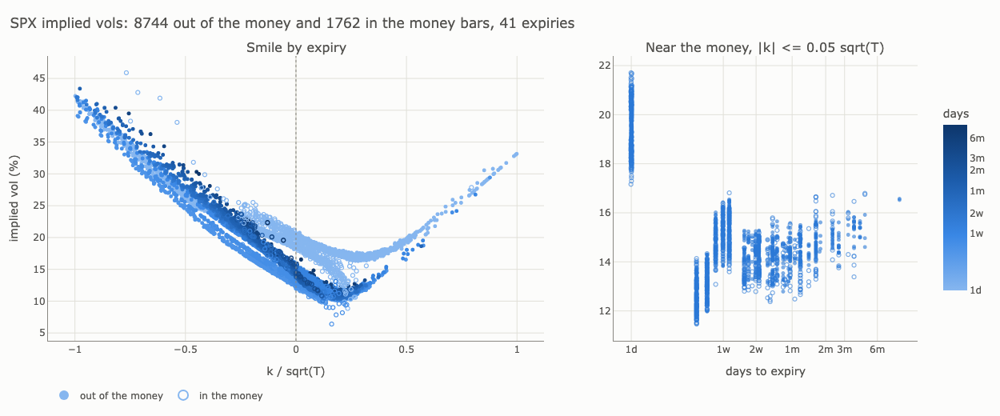

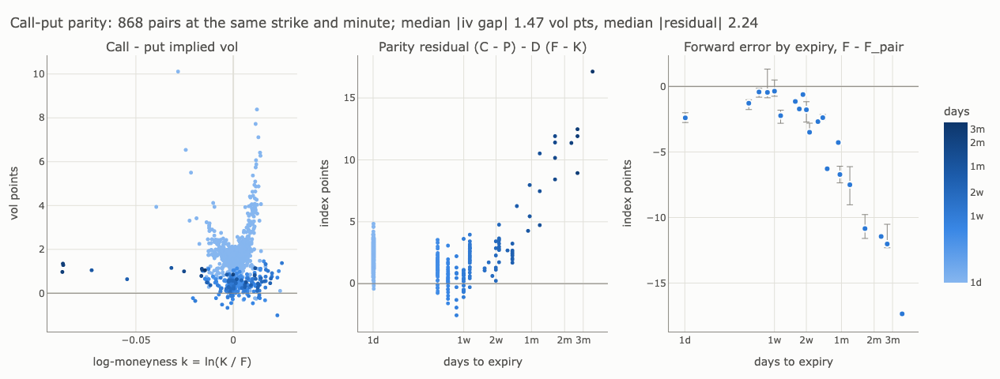

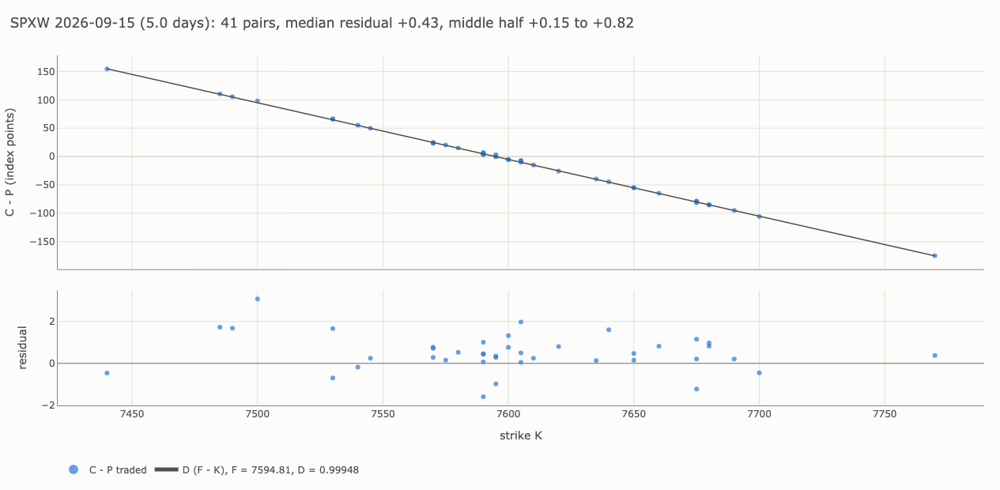

In [310]:
contract_vols = contract_vol_summary(df_calibration_iv, combine=False)   # per minute (needed for parity)

plot_smiles(contract_vols, side="both", standardized=True).show()                    # raw IVs, out of the money filled, in the money hollow
plot_price_3d(contract_vols, side="itm").show()                       # price: "otm" | "itm" | "both"
plot_iv_3d(contract_vols, side="otm", show_parity=True).show()        # IV surface + call-put pairs
plot_price_and_iv_3d(contract_vols, price_side="both", iv_side="otm", show_parity=True).show()

plot_parity_check(contract_vols).show()                               # every pair: IV gap, residual, forward error
plot_parity_expiry(contract_vols, "2026-09-15").show()                # drill into one expiry

### Problems

1. we can see that the implied vol computed from otm and itm are a bit different;
2. the call-put parity seems not to be very exact
3. some option contracts prices are out of the bound, that's why we see some iv in df_calibration_iv is NaN. 

### Two possible reasons I can think of for now: 
1. we are using the minute aggregation data, not real time quote data
2. we are using treasury yield curve and guessed dividends rate 0.011 for SPX 

In [268]:
### some inspections for the NaN iv 

df_temp = df_calibration_iv[df_calibration_iv.iv.isna()].iloc[[0]]

product=PRODUCT
dividend_yield = DIVIDEND_YIELD
curve = treasury_curve

out = df_temp.copy()
out["strike"] = out.strike.astype(float)  # nullable Float64 -> float
out["settlement"] = out.option_root.map(lambda root: product.settlement(root).value)
out["T"] = time_to_settlement(out.timestamp, out.expiration, out.settlement)
out["r"], out["discount"], out["forward"] = curve_forward(out.spot, out["T"], curve, dividend_yield)
out["k"] = np.log(out.strike / out.forward)

right = np.where(out.option_type == "call", 1, -1)
priceable = (out["T"] > 0) & out.spot.notna()

out

#### Further directions in the following development
1. vol surface calibration, also analyzing the vol surface dynamics
2. visualization a bit more with the existing code, see any problems with other stocks, maybe developing the web service app
3. more complicated options visualization
4. trading strategies